# CA1: MACHINE LEARNING - Parkinson's Disease Classification

Yasmina Lopez Roldan - sba25055

Github Link: https://github.com/sba25055-maker/CA1-Machine-Learning.git 

# Assigment Description

The type of question(s) that you should formulate for the assignment will depend on the chosen area of the dataset that you are considering for the machine learning assignment.

The following are suggested sample questions for possible analysis/assignments. These represent only a small selection, and you may adapt or expand them to better align with the specific focus of your assignment.

You are also encouraged to design your own questions based on your chosen area and dataset.

*  What are the most important features (X) for predicting Y as a target variable?
Which classification approach do you prefer for the prediction of Y as a target variable, and why?

*  How to classify the loyal and churn customers using Support Vector Machines rather than Random Forest classifier?

*  Why is dimensionality reduction important in your specific case?
The student would need to consider the following instructions (a - d) during the development of this assignment.

* Provide a logical justification for the selected machine learning approaches, explaining the reasoning behind their choice based on the problem characteristics and dataset properties.

* Develop at least two machine learning models, systematically selecting optimal hyperparameters, and compare their performance.

*  Visualize the comparison of machine learning model outcomes. Use statistical reasoning to demonstrate the significance of specific features and justify their impact on model performance.

*  Use cross-validation methods to validate the reliability and generalizability of your machine learning results.

## Importing Libraries
Importing libraries and adding import warning as a configuration to avoid unnecessary warnings in the dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# 1. Data Characterisation

### Data Information from the URL https://archive.ics.uci.edu/dataset/470/parkinson+s+disease+classification

**Dataset Information**
The data used in this study were gathered from 188 patients with Parkinson's disease (107 men and 81 women) ranging in age from 33 to 87 years (mean 65.1 $\pm$ 10.9) at the Department of Neurology in the Cerrahpaşa Faculty of Medicine, Istanbul University.

The control group consists of 64 healthy individuals (23 men and 41 women) ranging in age from 41 to 82 years (mean 61.1 $\pm$ 8.9). During the data collection process, the microphone was set to 44.1 kHz, and following the physician’s examination, the sustained phonation of the vowel /a/ was recorded from each subject with three repetitions.

**Variable Information**

Various speech signal processing algorithms—including time-frequency features, Mel-frequency cepstral coefficients (MFCCs), wavelet transform-based features, vocal fold features, and TWQT (Time-Frequency Wavelet Transform) features—have been applied to the speech recordings of Parkinson's disease (PD) patients to extract clinically useful information for PD assessment.

In [2]:
df = pd.read_csv('pd_speech_features.csv', header=1)
df.head()

,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
0,0,1,0.85247,0.71826,0.57227,240,239,0.008064,0.000087,0.00218,...,1.5620,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405,1
1,0,1,0.76686,0.69481,0.53966,234,233,0.008258,0.000073,0.00195,...,1.5589,3.6107,23.5155,14.1962,11.0261,9.5082,6.5245,6.3431,45.1780,1
2,0,1,0.85083,0.67604,0.58982,232,231,0.008340,0.000060,0.00176,...,1.5643,2.3308,9.4959,10.7458,11.0177,4.8066,2.9199,3.1495,4.7666,1
3,1,0,0.41121,0.79672,0.59257,178,177,0.010858,0.000183,0.00419,...,3.7805,3.5664,5.2558,14.0403,4.2235,4.6857,4.8460,6.2650,4.0603,1
4,1,0,0.32790,0.79782,0.53028,236,235,0.008162,0.002669,0.00535,...,6.1727,5.8416,6.0805,5.7621,7.7817,11.6891,8.2103,5.0559,6.1164,1


In [3]:
df.shape

(756, 755)

The dataset has 756 rows and 755 columns which is more than the minimun requested in the assigment "dataset should have at least 5 columns and more than 300 rows after pre-processing and cleaning".

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 756 entries, 0 to 755
Columns: 755 entries, id to class
dtypes: float64(749), int64(6)
memory usage: 4.4 MB


All my columns are numerical, float64(749), int64(6).

# 2. DATA PREPROCESSING AND CLEANING

### Checking for Null Values

In [5]:
print("Null values per column:\n", df.isnull().sum())

Null values per column:
 id                           0
gender                       0
PPE                          0
DFA                          0
RPDE                         0
                            ..
tqwt_kurtosisValue_dec_33    0
tqwt_kurtosisValue_dec_34    0
tqwt_kurtosisValue_dec_35    0
tqwt_kurtosisValue_dec_36    0
class                        0
Length: 755, dtype: int64


There is no null values in the Dataset


### Checking for Duplicates

In [6]:
df.duplicated().sum()

np.int64(1)

As there is only one duplicate I will drop it from the dataset

In [7]:
df = df.drop_duplicates()
print("New dataset shape:", df.shape)

New dataset shape: (755, 755)


My dataset is now clean but given the high dimensionality of the dataset, applying Principal Component Analysis (PCA) will be essential to streamline the feature space before modeling.

# 3. Exploratory Data Analysis

I will look closely at our features to understand their distribution, relationships, and potential impact on the target variable.

### Target Class Distribution (Count Plot)

In [8]:
class_counts = df['class'].value_counts()
print(class_counts)

class
1    563
0    192
Name: count, dtype: int64


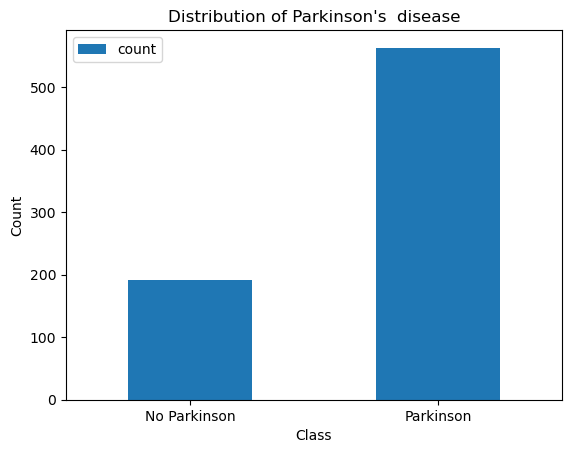

In [9]:
counted_class = df['class'].value_counts()
dataframe_for_plotting_class = pd.DataFrame({'class': ['No Parkinson', 'Parkinson'], 'count': [counted_class[0], counted_class[1]] })
ax = dataframe_for_plotting_class.plot.bar(x='class', y='count', rot=0)
ax.set_xlabel('Class')
ax.set_ylabel('Count')
ax.set_title("Distribution of Parkinson's  disease")
plt.show()

This bar chart shows a class imbalance between healthy patients ("No Parkinson") and Parkinson's disease patients ("Parkinson"), with 192 and 563 samples respectively.

### Feature Distribution by Class

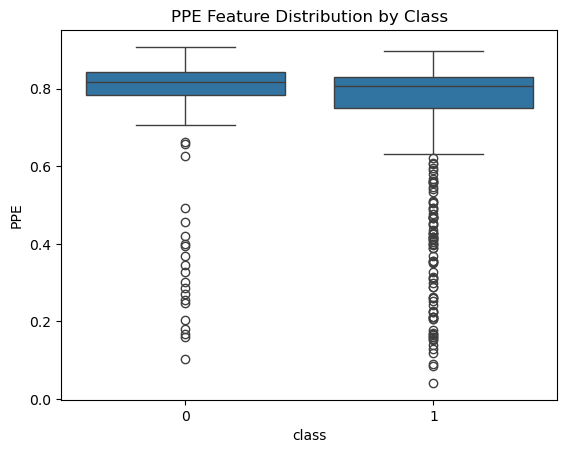

In [10]:
sns.boxplot(data=df, x='class', y='PPE')
plt.title('PPE Feature Distribution by Class')
plt.show()

While median PPE levels are similar in both groups, Parkinson's patients show a much wider spread and lower outliers, meaning a bigger vocal instability.

### Distribution by Gender and Class

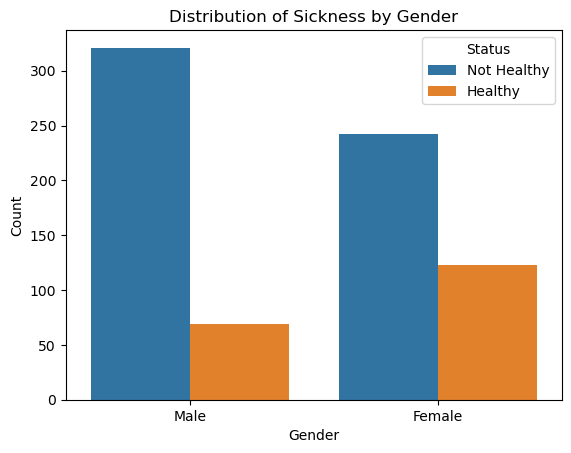

In [11]:
df_plot = df.copy()
df_plot['gender'] = df_plot['gender'].map({0: 'Female', 1: 'Male'})
df_plot['class'] = df_plot['class'].map({0: 'Healthy', 1: 'Not Healthy'})

sns.countplot(data=df_plot, x='gender', hue='class')
plt.title('Distribution of Sickness by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='Status')
plt.show()

### Feature Correlation with the Target

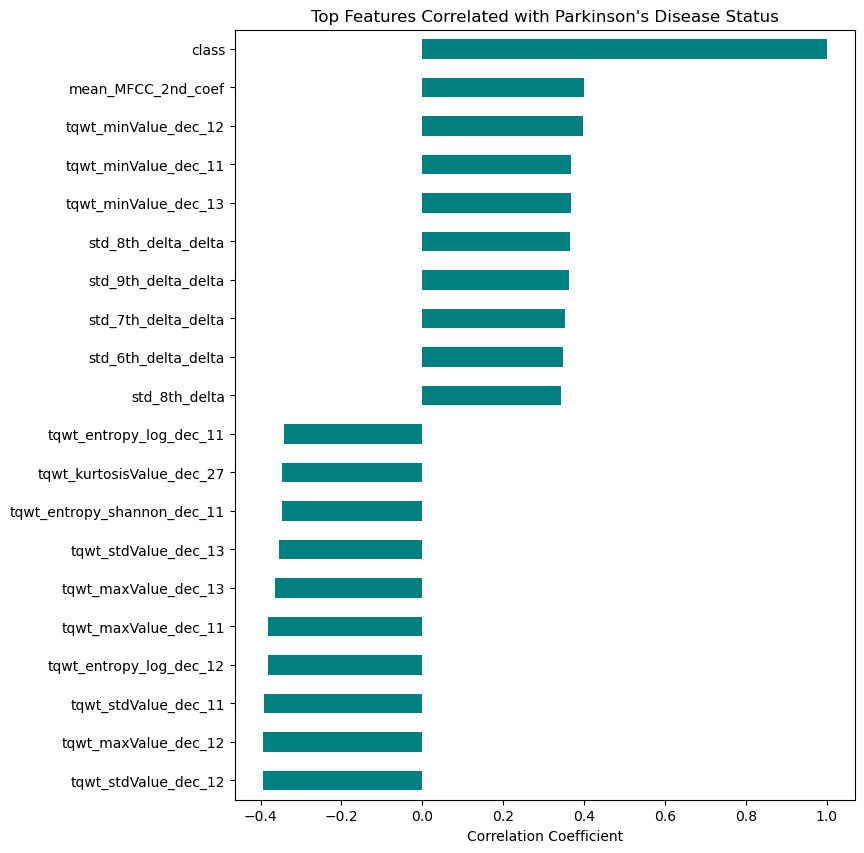

In [12]:
plt.figure(figsize=(8, 10))
correlations = df.drop(['id', 'gender'], axis=1).corr()['class'].sort_values()
top_corr = pd.concat([correlations.head(10), correlations.tail(10)])

top_corr.plot(kind='barh', color='teal')
plt.title('Top Features Correlated with Parkinson\'s Disease Status')
plt.xlabel('Correlation Coefficient')
plt.show()

This chart shows the features with the strongest linear correlation to Parkinson's disease from positive to negatve correlation. Features like as mean_MFCC_2nd_coef and some Tunable Q-factor Wavelet Transform (TQWT) metrics show positive correlations, while other TQWT entropy and statistical measures shows negative correlations.

### Correlation Matrix of First 10 Acoustic Features

As the dataset is too large I will be using "iloc 2:12" to specify the  columns from index position 2 to 11, as 0 and 1 are ID and Gender

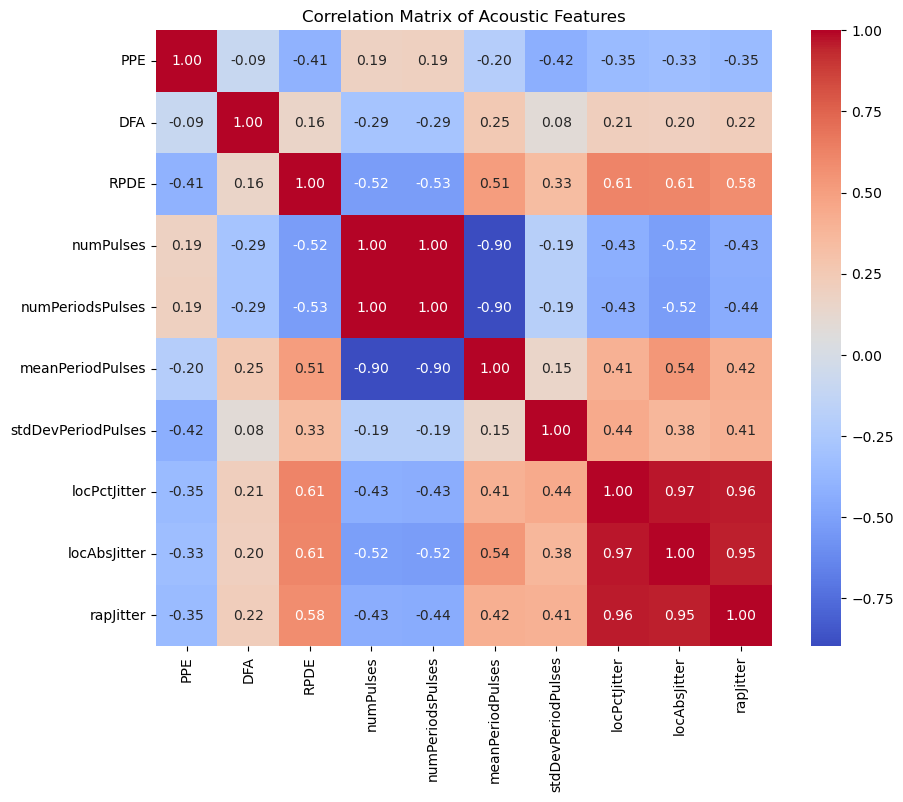

In [13]:
subset_features = df.iloc[:, 2:12]

corr_matrix = subset_features.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', cbar=True, square=True)
plt.title('Correlation Matrix of Acoustic Features')
plt.show()

The heatmap shows that jitter and pulse metrics heavily overlap, while features like PPE, DFA, and RPDE capture unique, independent aspects of the voice data.

# 4. Principal Component Analysis (PCA)
Since the dataset we have 753 features and 755 records, I will apply PCA to reduce dimensionality and avoid data redundancy.

(Jolliffe and Cadima, 2016)

First I will Separate features (X) and target variable (y)

Excluding 'id' (patient identifier) and 'class' (target)

In [14]:
X = df.drop(columns=['id', 'class'])
y = df['class']

Now Im going to scale the data which is essential to apply PCA

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

Applying PCA

In [16]:
from sklearn.decomposition import PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

I will calculate cumulative explained variance and plot it

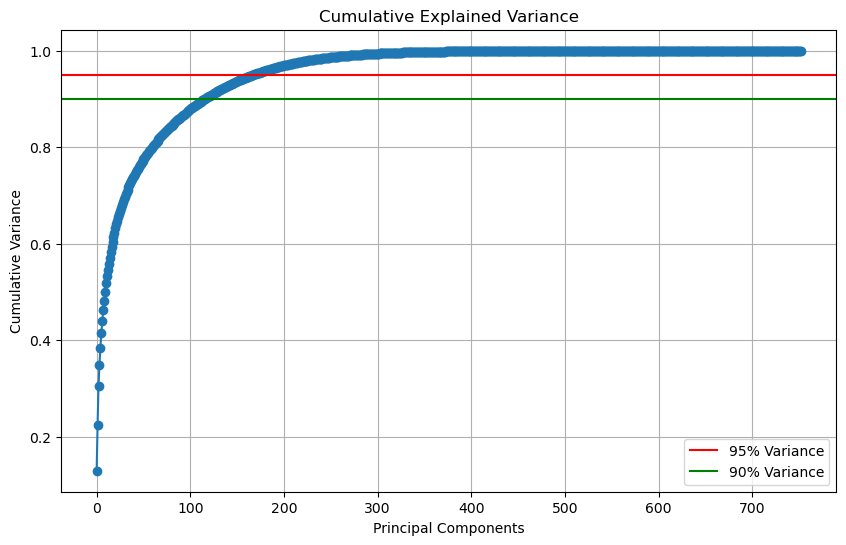

In [17]:
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(10, 6))
plt.plot(cumulative_variance, marker='o')
plt.axhline(0.95, color='r', label='95% Variance')
plt.axhline(0.90, color='g', label='90% Variance')
plt.title('Cumulative Explained Variance')
plt.xlabel('Principal Components')
plt.ylabel('Cumulative Variance')
plt.legend()
plt.grid(True)
plt.show()

Components needed for 90% and 95% variance

In [18]:
n_90 = np.argmax(cumulative_variance >= 0.90) + 1
n_95 = np.argmax(cumulative_variance >= 0.95) + 1
print(f"Number of components to retain 90% of the variance: {n_90}")
print(f"Number of components to retain 95% of the variance: {n_95}")

Number of components to retain 90% of the variance: 117
Number of components to retain 95% of the variance: 168


**Massive Reduction:** PCA reduce the feature space from 753 characteristics down to just 117 or 168 components, dramatically decreasing computational complexity.

**Prevention of Overfitting:** With 755 records and 753 columns, a model would simply memorize the data noise rather than learning generalizable patterns. Reducing the data to principal components effectively eliminates that noise.

**Elimination of Redundancy**: Because many voice measurements evaluate similar acoustic properties, PCA groups this redundant information in an optimal manner.

*Abid Ali Awan (2023).

### Fitting PCA into my X_scaled

In [19]:
pca_95 = PCA(n_components=0.95, random_state=42)
X_pca = pca_95.fit_transform(X_scaled)
print(f"New dimension of X_pca (95% variance): {X_pca.shape}")

New dimension of X_pca (95% variance): (755, 168)


## Showing the reduction with PCA

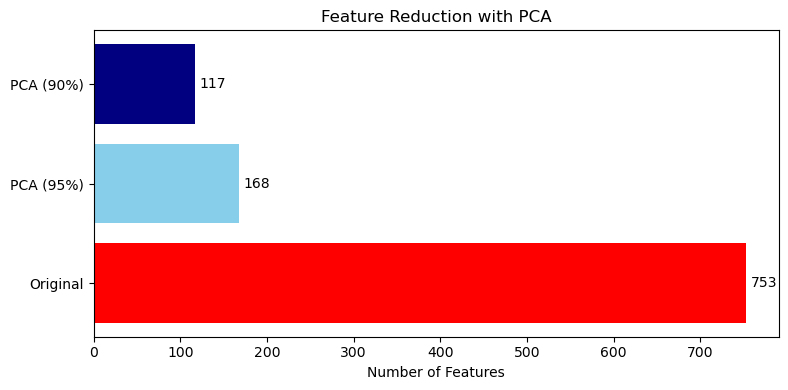

In [20]:
sizes = [X.shape[1], n_95, n_90]
categories = ['Original', 'PCA (95%)', 'PCA (90%)']

plt.figure(figsize=(8, 4))
bars = plt.barh(categories, sizes, color=['red', 'skyblue', 'navy'])

plt.title('Feature Reduction with PCA')
plt.xlabel('Number of Features')

for bar in bars:
    plt.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2, str(bar.get_width()), va='center')

plt.tight_layout()
plt.savefig('pca_dimension_reduction_comparison.png', dpi=300)
plt.show()

# 5. Machine Learning Models

I chose Support Vector Machines (SVM) and Random Forest because they let us compare two totally different ways of looking at the data. SVM is good in high-dimensional spaces, handles tricky non-linear voice patterns using RBF kernels, and delivers the high clinical recall I need for this dataset. At the same time, Random Forest is great at dealing with noisy, overlapping features through tree-averaging, giving us a really solid baseline for diagnostic classification.

(scikit-learn, 2018) (GeeksforGeeks, 2024)

In [21]:
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score

To evaulate data efficiency I will be running two models across three different training set sizes (5%, 15%, and 25%) using PCA-reduced data, and showing key performance metrics (Accuracy, Precision, Recall, and F1-score) in a table.

In [22]:
classifiers = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Support Vector Machine": SVC(kernel='linear', random_state=42)
}

all_results = []

for train_size in [0.05, 0.15, 0.25]:
    X_train, X_test, y_train, y_test = train_test_split(
        X_pca, y, train_size=train_size, random_state=42, stratify=y
    )

    for name, clf in classifiers.items():
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)

        report = classification_report(y_test, y_pred, output_dict=True, zero_division=0)

        all_results.append({
            'Train Size (%)': int(train_size * 100),
            'Classifier': name,
            'Test Accuracy': round(accuracy_score(y_test, y_pred), 4),
            'Precision': round(report['weighted avg']['precision'], 4),
            'Recall': round(report['weighted avg']['recall'], 4),
            'F1-Score': round(report['weighted avg']['f1-score'], 4)
        })

results_df = pd.DataFrame(all_results)
print(results_df.to_string(index=False))

 Train Size (%)             Classifier  Test Accuracy  Precision  Recall  F1-Score
              5          Random Forest         0.7465     0.7099  0.7465    0.6446
              5 Support Vector Machine         0.8036     0.7910  0.8036    0.7922
             15          Random Forest         0.7523     0.7133  0.7523    0.6781
             15 Support Vector Machine         0.8224     0.8140  0.8224    0.8156
             25          Random Forest         0.7478     0.6981  0.7478    0.6768
             25 Support Vector Machine         0.8113     0.8109  0.8113    0.8111


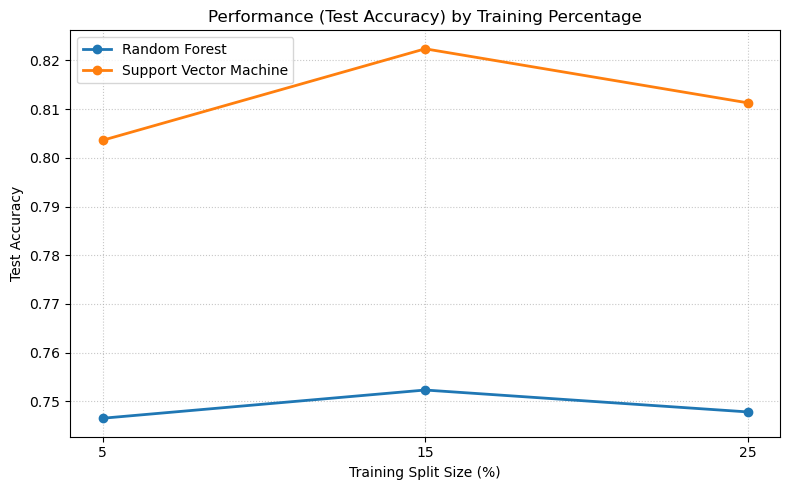

In [23]:
plt.figure(figsize=(8,5 ))
results_df.pivot(index='Train Size (%)', columns='Classifier', values='Test Accuracy').plot(
    marker='o', linewidth=2, ax=plt.gca()
)

plt.title('Performance (Test Accuracy) by Training Percentage')
plt.xlabel('Training Split Size (%)')
plt.ylabel('Test Accuracy')
plt.xticks([5, 15, 25])
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(title='')
plt.tight_layout()
plt.savefig('split_performance_comparison.png', dpi=300)
plt.show()

Across all three splits, SVM outperforms Random Forest in test accuracy (80.4–82.2% vs 74.7–75.2%) and F1-score. Test accuracy peaks at 15% for both models, but differences between splits are small, so accuracy is essentially flat from 5% to 25% training data.

### Adding 5 Fold Cross-Validation to each training size (5%, 15% and 25%)

I will add 5 Fold Cross-Validation with StratifiedKfold to the training loop. For each training size (5%, 15%, 25%), I will split the training data itself into 5 parts, training on 4 and validating on 1, repeating this 5 times, to calculate the mean accuracy and standard deviation.

(scikit-learn, 2019)

In [24]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []
for train_size in [0.05, 0.15, 0.25]:
    X_train, X_test, y_train, y_test = train_test_split(
        X_pca, y, train_size=train_size, random_state=42, stratify=y
    )
    for name, clf in classifiers.items():
        cv_scores = cross_val_score(clf, X_train, y_train, cv=cv, scoring='accuracy')
        test_acc = clf.fit(X_train, y_train).score(X_test, y_test)

        cv_results.append({
            'Train Size (%)': int(train_size * 100),
            'Classifier': name,
            'CV Mean Acc': round(cv_scores.mean(), 4),
            'CV Std': round(cv_scores.std(), 4),
            'Test Acc': round(test_acc, 4)
        })

cv_df = pd.DataFrame(cv_results)
print(cv_df.to_string(index=False))

 Train Size (%)             Classifier  CV Mean Acc  CV Std  Test Acc
              5          Random Forest       0.7571  0.0525    0.7465
              5 Support Vector Machine       0.8357  0.1000    0.8036
             15          Random Forest       0.7439  0.0404    0.7523
             15 Support Vector Machine       0.7960  0.0543    0.8224
             25          Random Forest       0.7504  0.0375    0.7478
             25 Support Vector Machine       0.8087  0.0507    0.8113


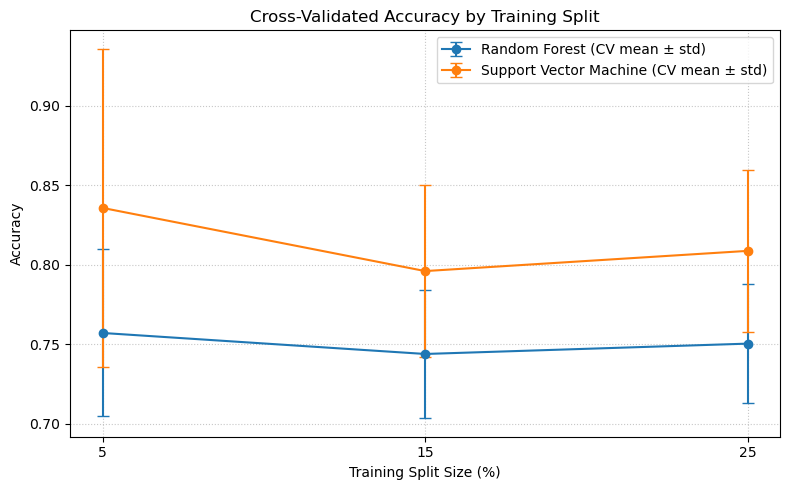

In [25]:
fig, ax = plt.subplots(figsize=(8, 5))
for name in cv_df['Classifier'].unique():
    d = cv_df[cv_df['Classifier'] == name]
    ax.errorbar(d['Train Size (%)'], d['CV Mean Acc'], yerr=d['CV Std'],
                marker='o', capsize=4, label=f'{name} (CV mean ± std)')
ax.set(xlabel='Training Split Size (%)', ylabel='Accuracy',
       title='Cross-Validated Accuracy by Training Split', xticks=[5, 15, 25])
ax.grid(True, linestyle=':', alpha=0.7)
ax.legend()
plt.tight_layout()
plt.show()

Support Vector Machine consistently outperforms Random Forest across all training sizes, with a higher CV Mean Accuracy.

Increasing the training size from 5% to 25% does not significantly improve accuracy for either model.

# 6. HYPERPARAMETER TUNING (using the 25% split)

I'm going to use GridSearch for hyperparameter tuning with the 25% split so it will have more data to work it. I want to see if the models' default settings were holding them back, and whether finding the optimal parameters can improve your classification results (like precision, recall, and F1-score) for detecting Parkinson's.

(Scikit-learn.org, 2026)

In [26]:
X_train_25, X_test_25, y_train_25, y_test_25 = train_test_split(
    X_pca, y, train_size=0.25, random_state=42, stratify=y
)

models = [
    ("RANDOM FOREST", RandomForestClassifier(random_state=42), {'n_estimators': [50, 100, 150], 'max_depth': [5, 10, None]}),
    ("SVM", SVC(random_state=42), {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']})
]

fitted_grids = {}

for name, clf, params in models:
    gs = GridSearchCV(clf, params, cv=3, scoring='accuracy', n_jobs=-1).fit(X_train_25, y_train_25)

    fitted_grids[name] = gs

    print(f"\n--- {name} ---")
    print(f"Best Params: {gs.best_params_} | CV Accuracy: {gs.best_score_:.4f}")
    print(classification_report(
        y_test_25, gs.predict(X_test_25),
        target_names=['No Parkinson (0)', 'Parkinson (1)'], zero_division=0
    ))

grid_rf = fitted_grids["RANDOM FOREST"]
grid_svm = fitted_grids["SVM"]


--- RANDOM FOREST ---
Best Params: {'max_depth': 5, 'n_estimators': 150} | CV Accuracy: 0.7447
                  precision    recall  f1-score   support

No Parkinson (0)       0.50      0.01      0.01       144
   Parkinson (1)       0.75      1.00      0.85       423

        accuracy                           0.75       567
       macro avg       0.62      0.50      0.43       567
    weighted avg       0.68      0.75      0.64       567


--- SVM ---
Best Params: {'C': 10, 'kernel': 'rbf'} | CV Accuracy: 0.8244
                  precision    recall  f1-score   support

No Parkinson (0)       0.73      0.57      0.64       144
   Parkinson (1)       0.86      0.93      0.89       423

        accuracy                           0.84       567
       macro avg       0.79      0.75      0.77       567
    weighted avg       0.83      0.84      0.83       567



Again Support Vector Machine (SVM) clearly outperforms Random Forest, achieving 84% accuracy and a weighted F1-score of 0.83 (compared to Random Forest's 75% and 0.64).

Random Forest's accuracy looks okay, but diagnostically it falls apart because of class imbalance. It essentially guesses "Parkinson's" for almost everyone,catching 100% of the actual cases (423/423), but correctly identifying only one healthy patient out of 144. However, SVM works well, maintaining high clinical safety with a 93% Parkinson's recall (393/423) while correctly identifying 57% of healthy patients (82/144).

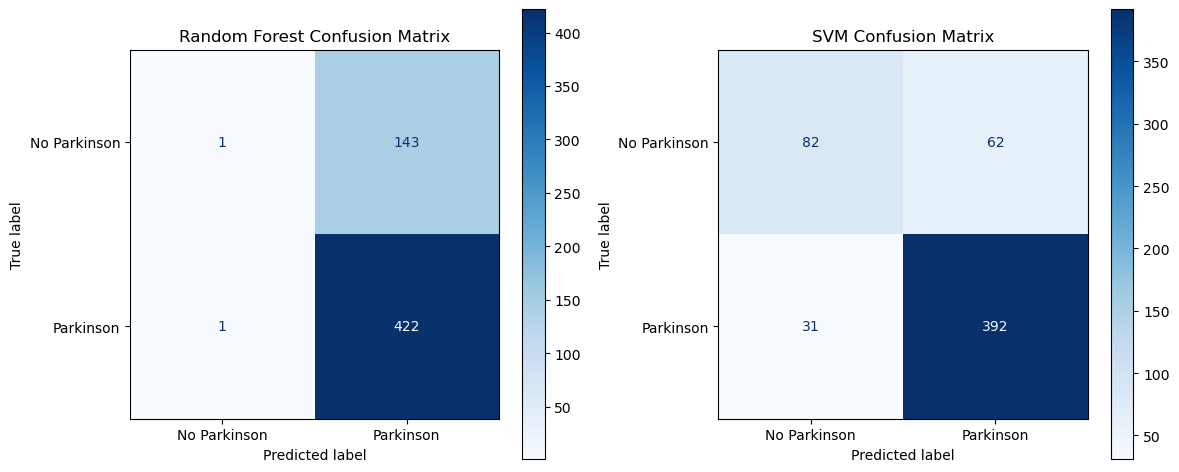

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay

rf = RandomForestClassifier(n_estimators=150, max_depth=5, random_state=42).fit(X_train_25, y_train_25)
svm = SVC(C=10, kernel='rbf', random_state=42).fit(X_train_25, y_train_25)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_estimator(rf, X_test_25, y_test_25, display_labels=['No Parkinson', 'Parkinson'], cmap='Blues', ax=axes[0])
axes[0].set_title('Random Forest Confusion Matrix')

ConfusionMatrixDisplay.from_estimator(svm, X_test_25, y_test_25, display_labels=['No Parkinson', 'Parkinson'], cmap='Blues', ax=axes[1])
axes[1].set_title('SVM Confusion Matrix')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=300)
plt.show()

Confusion Matrix Explanation & Insights:

Random Forest: It catches every single Parkinson's case (0 false negatives), but it completely fails on healthy patients, mislabeling 143 out of 144 as sick. Because it just defaults to predicting the majority class, it's clinically useless.

Support Vector Machine: SVM successfully identifies over half of the healthy controls and gets a strong 93% recall rate for actual Parkinson's cases, making it clearly the better model for deployment.

(scikit-learn, n.d.)

### Bar Chart comparing default dataset vs tuned dataset with the 25% split

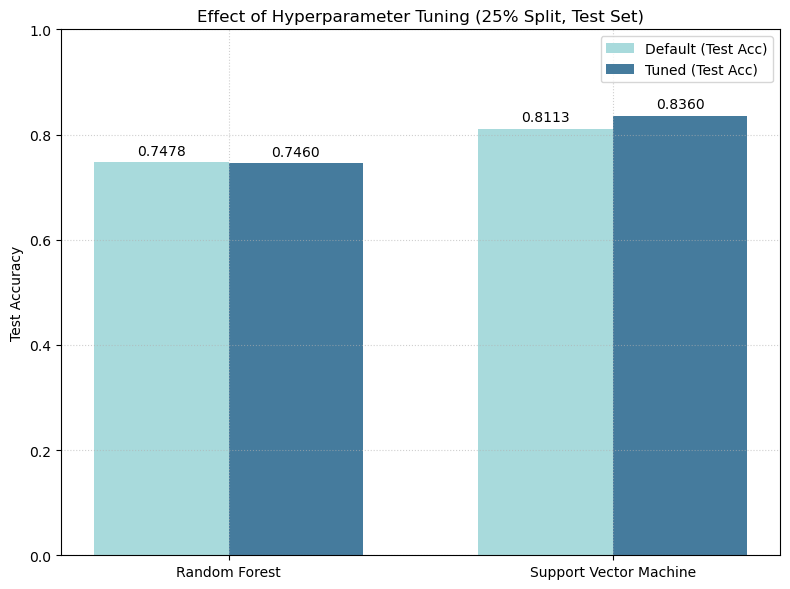

In [28]:
labels = ['Random Forest', 'Support Vector Machine']

before = [results_df.query("Classifier == @m and `Train Size (%)` == 25")['Test Accuracy'].iloc[0]
          for m in labels]

after = [grid_rf.best_estimator_.score(X_test_25, y_test_25),
         grid_svm.best_estimator_.score(X_test_25, y_test_25)]

x, width = np.arange(len(labels)), 0.35
fig, ax = plt.subplots(figsize=(8, 6))
r1 = ax.bar(x - width/2, before, width, label='Default (Test Acc)', color='#a8dadc')
r2 = ax.bar(x + width/2, after,  width, label='Tuned (Test Acc)',   color='#457b9d')

ax.set(ylabel='Test Accuracy', title='Effect of Hyperparameter Tuning (25% Split, Test Set)',
       xticks=x, xticklabels=labels, ylim=(0, 1.0))
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend()
for rects in (r1, r2):
    ax.bar_label(rects, fmt='%.4f', padding=3)
plt.tight_layout()
plt.savefig('hyperparameter_tuning_comparison.png', dpi=300)
plt.show()

**Chart Analysis**

Random Forest: test accuracy is basically the same because it still predicts almost every sample as Parkinson.

SVM: test accuracy rises from 81.13% to 83.60% . Both bars use the same 25% test set, so the comparison is fair.

# Cross validation

I will re used the tune models to test it with 5 fold cross validation.

In [29]:
rf_scores = cross_val_score(grid_rf.best_estimator_, X_pca, y, cv=5, scoring='accuracy')
svm_scores = cross_val_score(grid_svm.best_estimator_, X_pca, y, cv=5, scoring='accuracy')

print("Mean CV Accuracy (Random Forest):", round(rf_scores.mean(), 4))
print("Mean CV Accuracy (SVM):", round(svm_scores.mean(), 4))

Mean CV Accuracy (Random Forest): 0.751
Mean CV Accuracy (SVM): 0.8026


Across 5-fold cross-validation, SVM clearly wins with an average accuracy of 80.3%, beating Random Forest's 75.1%.

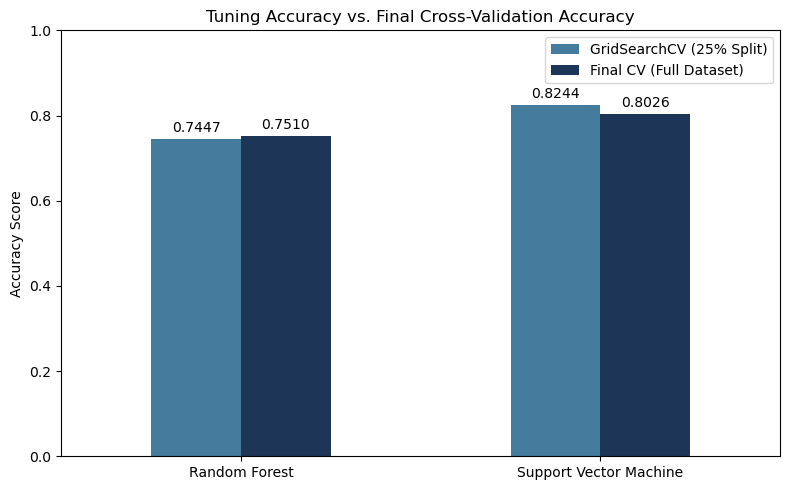

In [30]:
df_plot = pd.DataFrame({
    'GridSearchCV (25% Split)': [grid_rf.best_score_, grid_svm.best_score_],
    'Final CV (Full Dataset)': [rf_scores.mean(), svm_scores.mean()]
}, index=['Random Forest', 'Support Vector Machine'])

ax = df_plot.plot(kind='bar', rot=0, ylim=(0, 1.0), color=['#457b9d', '#1d3557'], figsize=(8, 5))
ax.set_ylabel('Accuracy Score')
ax.set_title('Tuning Accuracy vs. Final Cross-Validation Accuracy')

for container in ax.containers:
    ax.bar_label(container, fmt='%.4f', padding=3)

plt.tight_layout()
plt.show()

SVM clearly wins, maintaining roughly 80% - 82% accuracy across tuning and cross-validation;

Random Forest does not work because of the class imbalance, it predicts almost everyone as having Parkinson's, making it clinically unusable. SVM gets a safe, 93% recall for Parkinson's and 57% correct identification of healthy controls.